# CT4101 Milestone 2: Data and baseline checkpoint

## 1. Setup

In [1]:
import gc, json, os, sys, time
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, os.path.abspath("../src"))
from data import FAMILY, SEED, audit, conflict_mask, feature_cols, load_raw, near_identical, prepare, row_hash
from features import PORT, preprocessor
from evaluate import BENIGN, cv_evaluate

pd.set_option("display.max_columns", 50, "display.width", 200)
REPORTS = "../reports"
os.makedirs(REPORTS, exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

python 3.11.4 | numpy 2.4.4 | pandas 3.0.2 | sklearn 1.8.0


## 2. Load the raw data

In [2]:
t = time.time()
raw = load_raw()
print(raw.shape, f"{time.time() - t:.0f}s", f"{raw.memory_usage(deep=True).sum() / 1e9:.2f} GB")
raw.head(3)

(2830743, 80) 15s 1.77 GB


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,...,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,session
0,54865.0,3.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3.0,3.0,3.0,3.0,0.0,3.0,3.0,...,40.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,12.0,0.0,0.0,33.0,-1.0,1.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,55054.0,109.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,6.0,6.0,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109.0,109.0,0.0,0.0,0.0,0.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.0,1.0,6.0,29.0,256.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,55055.0,52.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,6.0,6.0,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52.0,52.0,0.0,0.0,0.0,0.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.0,1.0,6.0,29.0,256.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


## 3. Data audit
### 3.1 Labels and class balance

In [3]:
A = audit(raw)
lab = pd.Series(A["label_counts"]).rename("rows").to_frame()
lab["share_%"] = (100 * lab["rows"] / A["rows"]).round(4)
lab["family"] = [FAMILY[l] or "(excluded)" for l in lab.index]
lab

,rows,share_%,family
BENIGN,2273097,80.3004,Benign
DoS Hulk,231073,8.1630,DoS
PortScan,158930,5.6144,PortScan
DDoS,128027,4.5227,DDoS
DoS GoldenEye,10293,0.3636,DoS
FTP-Patator,7938,0.2804,BruteForce
SSH-Patator,5897,0.2083,BruteForce
DoS slowloris,5796,0.2048,DoS
DoS Slowhttptest,5499,0.1943,DoS
Bot,1966,0.0695,Bot


### 3.2 Which attacks occur in which session

In [4]:
sess = (raw.groupby(["session", "Label"], observed=True).size().unstack(fill_value=0))
sess.loc[:, sess.columns != "BENIGN"].replace(0, "")

Label,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack Brute Force,Web Attack Sql Injection,Web Attack XSS
session,,,,,,,,,,,,,,
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,,128027,,,,,,,,,,,,
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,,,,,,,,,,158930,,,,
Friday-WorkingHours-Morning.pcap_ISCX.csv,1966,,,,,,,,,,,,,
Monday-WorkingHours.pcap_ISCX.csv,,,,,,,,,,,,,,
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,,,,,,,,,36,,,,,
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,,,,,,,,,,,,1507,21,652
Tuesday-WorkingHours.pcap_ISCX.csv,,,,,,,7938,,,,5897,,,
Wednesday-workingHours.pcap_ISCX.csv,,,10293,231073,5499,5796,,11,,,,,,


### 3.3 Missing, infinite and negative values

In [5]:
X0 = raw[feature_cols(raw)]
dur0 = raw["Flow Duration"] == 0
vals = pd.DataFrame({
    "nan": pd.Series(A["nan"]), "inf": pd.Series(A["inf"]), "negative": pd.Series(A["negative"]),
}).fillna(0).astype(int)
vals["negative_values_seen"] = [sorted(X0.loc[X0[c] < 0, c].unique())[:4] if vals.loc[c, "negative"] else "" for c in vals.index]
print("zero-duration flows:", int(dur0.sum()),
      "| NaN Flow Bytes/s with zero duration:", int((raw["Flow Bytes/s"].isna() & dur0).sum()),
      "| inf Flow Packets/s with zero duration:", int((np.isinf(raw["Flow Packets/s"]) & dur0).sum()))
vals

zero-duration flows: 2867 | NaN Flow Bytes/s with zero duration: 1358 | inf Flow Packets/s with zero duration: 2867


,nan,inf,negative,negative_values_seen
Bwd Header Length,0,0,22,"[-1073741320.0, -1073741218.0, -1073740992.0, ..."
Flow Bytes/s,1358,1509,85,"[-261000000.0, -193000000.0, -12000000.0, -800..."
Flow Duration,0,0,115,"[-13.0, -12.0, -4.0, -2.0]"
Flow IAT Max,0,0,115,"[-13.0, -12.0, -4.0, -2.0]"
Flow IAT Mean,0,0,115,"[-13.0, -12.0, -4.0, -2.0]"
Flow IAT Min,0,0,2891,"[-14.0, -13.0, -12.0, -11.0]"
Flow Packets/s,0,2867,115,"[-2000000.0, -1000000.0, -500000.0, -166666.6667]"
Fwd Header Length,0,0,35,"[-32212234632.0, -9663668122.0, -6442447920.0,..."
Fwd Header Length.1,0,0,35,"[-32212234632.0, -9663668122.0, -6442447920.0,..."
Fwd IAT Min,0,0,17,"[-12.0, -8.0, -1.0]"


### 3.4 Shortcut check: `Init_Win_bytes_forward = -1` by class

In [6]:
iw = raw.groupby("Label", observed=True)["Init_Win_bytes_forward"].agg(rows="size", minus1=lambda s: int((s == -1).sum()))
iw["share"] = (iw["minus1"] / iw["rows"]).round(4)
iw.sort_values("rows", ascending=False)

,rows,minus1,share
Label,,,
BENIGN,2273097,1001182,0.4404
DoS Hulk,231073,0,0.0000
PortScan,158930,7,0.0000
DDoS,128027,0,0.0000
DoS GoldenEye,10293,0,0.0000
FTP-Patator,7938,0,0.0000
SSH-Patator,5897,0,0.0000
DoS slowloris,5796,0,0.0000
DoS Slowhttptest,5499,0,0.0000


### 3.5 Shortcut check: destination-port concentration per attack

In [7]:
att = raw[raw["Label"] != "BENIGN"]
port = att.groupby("Label", observed=True)[PORT].agg(
    top_port=lambda s: int(s.mode().iloc[0]),
    top_port_share=lambda s: round(float(s.value_counts(normalize=True).iloc[0]), 4),
    distinct_ports="nunique")
port["benign_share_on_that_port"] = [round(float((raw.loc[raw["Label"] == "BENIGN", PORT] == p).mean()), 4) for p in port["top_port"]]
del att
port

,top_port,top_port_share,distinct_ports,benign_share_on_that_port
Label,,,,
Bot,8080,0.6414,706,0.0006
DDoS,80,1.0000,4,0.1037
DoS GoldenEye,80,1.0000,1,0.1037
DoS Hulk,80,1.0000,1,0.1037
DoS Slowhttptest,80,1.0000,1,0.1037
DoS slowloris,80,1.0000,1,0.1037
FTP-Patator,21,0.9999,2,0.0023
Heartbleed,444,1.0000,1,0.0000
Infiltration,444,1.0000,1,0.0000


### 3.6 Redundant columns

In [8]:
ni = near_identical(raw, feature_cols(raw))
red = pd.DataFrame(
    [(c, "constant", "", "") for c in A["constant"]]
    + [(a, "identical", b, 0.0) for a, b in A["identical"] if a not in A["constant"]]
    + [(a, "near-identical", b, d) for a, b, d in ni if d > 0],
    columns=["column", "kind", "copy_of", "max_rel_diff"])
DROP = sorted(red["column"])
print(len(DROP), "columns dropped →", len(feature_cols(raw)) - len(DROP), "features remain")
red

15 columns dropped → 63 features remain


,column,kind,copy_of,max_rel_diff
0,Bwd PSH Flags,constant,,
1,Bwd URG Flags,constant,,
2,Fwd Avg Bytes/Bulk,constant,,
3,Fwd Avg Packets/Bulk,constant,,
4,Fwd Avg Bulk Rate,constant,,
5,Bwd Avg Bytes/Bulk,constant,,
6,Bwd Avg Packets/Bulk,constant,,
7,Bwd Avg Bulk Rate,constant,,
8,SYN Flag Count,identical,Fwd PSH Flags,0.0
9,CWE Flag Count,identical,Fwd URG Flags,0.0


### 3.7 Duplicates and conflicting labels

In [9]:
dup = pd.Series({
    "exact duplicate rows (features + label)": A["exact_dup_rows"],
    "feature-duplicate rows (features only)": A["feature_dup_rows"],
    "feature groups carrying >1 label": A["conflicting_groups"],
})
print(f"exact duplicates = {100 * A['exact_dup_rows'] / A['rows']:.2f}% of rows")
dup.to_frame("count")

exact duplicates = 10.89% of rows


,count
exact duplicate rows (features + label),308381
feature-duplicate rows (features only),309079
feature groups carrying >1 label,698


In [10]:
json.dump({**A, "near_identical": ni, "drop": DROP}, open(f"{REPORTS}/audit.json", "w"), indent=1, default=str)

## 5. Cleaning (`prepare`)

In [11]:
n_raw_kept = int(raw["Label"].astype(str).map(FAMILY).notna().sum())
df, FEATS = prepare(raw, DROP)
del raw, X0, dur0
gc.collect()
print(f"{n_raw_kept:,} rows in kept labels → {len(df):,} after both dedups ({n_raw_kept - len(df):,} removed) | {len(FEATS)} features")
fam = df["family"].value_counts().rename("rows").to_frame()
fam["share_%"] = (100 * fam["rows"] / len(df)).round(3)
fam

2,830,696 rows in kept labels → 2,499,496 after both dedups (331,200 removed) | 63 features


,rows,share_%
family,,
Benign,2073680,82.964
DoS,193733,7.751
DDoS,128016,5.122
PortScan,90819,3.633
BruteForce,9152,0.366
WebAttack,2143,0.086
Bot,1953,0.078


## 6. Split, then dev-only conflict removal

In [12]:
from sklearn.model_selection import train_test_split

dev, test = train_test_split(df, test_size=0.2, stratify=df["family"], random_state=SEED)
del df
gc.collect()
c_dev, c_test = conflict_mask(dev, FEATS), conflict_mask(test, FEATS)
dev = dev[~c_dev].reset_index(drop=True)
print(f"dev conflict rows dropped: {c_dev.sum():,} | test conflict rows kept (error floor): {c_test.sum():,} = {100 * c_test.mean():.4f}% of test")
split = pd.DataFrame({"dev": dev["family"].value_counts(), "test": test["family"].value_counts()})
split["test_%"] = (100 * split["test"] / (split["dev"] + split["test"])).round(2)
split

dev conflict rows dropped: 894 | test conflict rows kept (error floor): 54 = 0.0108% of test


,dev,test,test_%
family,,,
Benign,1658496,414737,20.00
DoS,154896,38747,20.01
DDoS,102411,25603,20.00
PortScan,72300,18164,20.08
BruteForce,7322,1830,20.00
WebAttack,1714,429,20.02
Bot,1563,390,19.97


In [13]:
TEST_ROWS = len(test)
del test
gc.collect()
X, y = dev[FEATS], dev["family"].to_numpy()

## 7. Preprocessing pipeline

In [14]:
pre = preprocessor(FEATS)
Z = pre.fit_transform(X.iloc[:200_000])
names = pre.get_feature_names_out()
print("input", X.shape[1], "→ output", Z.shape[1], "columns on a 200k fit")
print("indicators:", [n.replace("missingindicator_", "") for n in names if n.startswith("missingindicator_")])
print("ports:", [n.split("_")[1] for n in names if n.startswith(PORT)])
del Z
pre

input 63 → output 106 columns on a 200k fit
indicators: ['Flow Duration', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Min', 'Fwd Header Length', 'Bwd Header Length', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'min_seg_size_forward']
ports: ['0.0', '21.0', '22.0', '53.0', '80.0', '88.0', '123.0', '135.0', '137.0', '138.0', '139.0', '389.0', '443.0', '445.0', '465.0', '1037.0', '1041.0', '1042.0', '2725.0', '3268.0', '3809.0', '5353.0', '5355.0', '8080.0', '8089.0', '16992.0', '19842.0', '49666.0', '49671.0', '50006.0', '52822.0', 'infrequent']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('port', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. 

## 8. Evaluation design

In [15]:
p = pd.Series(y).value_counts(normalize=True)
p0, K = p[BENIGN], len(p)
print(f"predicted: prior macro-F1 = {2 * p0 / (K * (1 + p0)):.4f} | stratified ≈ {1 / K:.4f} | PR-AUC chance = attack share = {1 - p0:.4f}")

predicted: prior macro-F1 = 0.1296 | stratified ≈ 0.1429 | PR-AUC chance = attack share = 0.1702


## 9. Baseline results (5-fold CV on dev)

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

def pipe(model, feats=FEATS, **kw):
    return Pipeline([("pre", preprocessor(feats, **kw)), ("model", model)])

MODELS = {
    "dummy_prior": pipe(DummyClassifier(strategy="prior")),
    "dummy_stratified": pipe(DummyClassifier(strategy="stratified", random_state=SEED)),
    "logreg_balanced": pipe(LogisticRegression(class_weight="balanced", max_iter=1000)),
    "tree_d8_balanced": pipe(DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEED)),
}
FOLDS, OOF = {}, {}
for name, m in MODELS.items():
    t = time.time()
    FOLDS[name], OOF[name], _ = cv_evaluate(m, X, y, SEED)
    print(f"{name:18s} {time.time() - t:6.0f}s")

dummy_prior            67s
dummy_stratified       73s


In [ ]:
def summary(folds):
    rows = {}
    for name, f in folds.items():
        r = {}
        for c in ["val_macro_f1", "train_macro_f1", "val_bal_acc", "val_benign_fpr", "val_attack_recall", "val_pr_auc", "val_acc"]:
            r[c.replace("val_", "")] = f"{f[c].mean():.4f} ± {f[c].std(ddof=1):.4f}"
        rows[name] = r
    return pd.DataFrame(rows).T

RES = summary(FOLDS)
RES

,macro_f1,train_macro_f1,bal_acc,benign_fpr,attack_recall,pr_auc,acc
dummy_prior,0.1296 ± 0.0000,0.1296 ± 0.0000,0.1429 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.1702 ± 0.0000,0.8298 ± 0.0000
dummy_stratified,0.1428 ± 0.0005,0.1429 ± 0.0002,0.1428 ± 0.0005,0.1707 ± 0.0003,0.1697 ± 0.0014,0.1701 ± 0.0002,0.6981 ± 0.0003
logreg_balanced,0.7628 ± 0.0034,0.7630 ± 0.0034,0.9934 ± 0.0004,0.0373 ± 0.0008,0.9993 ± 0.0001,0.9968 ± 0.0003,0.9687 ± 0.0007
tree_d8_balanced,0.7593 ± 0.0052,0.7596 ± 0.0057,0.9935 ± 0.0013,0.0258 ± 0.0008,0.9996 ± 0.0002,0.9966 ± 0.0006,0.9780 ± 0.0006


### 9.1 Per-class diagnostics (out-of-fold)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

ORDER = list(p.index)
rep = {n: pd.DataFrame(classification_report(y, OOF[n], labels=ORDER, output_dict=True, zero_division=0)).T.loc[ORDER, ["precision", "recall", "f1-score", "support"]]
       for n in ["logreg_balanced", "tree_d8_balanced"]}
pd.concat(rep, axis=1).round(4)

logreg_balanced                             tree_d8_balanced                            
                 precision  recall f1-score    support        precision  recall f1-score    support
Benign              0.9998  0.9627   0.9809  1658496.0           0.9999  0.9742   0.9869  1658496.0
DoS                 0.9537  0.9971   0.9749   154896.0           0.9614  0.9947   0.9777   154896.0
DDoS                0.9936  0.9995   0.9965   102411.0           0.9963  0.9992   0.9977   102411.0
PortScan            0.9790  0.9982   0.9885    72300.0           0.9890  0.9972   0.9931    72300.0
BruteForce          0.9478  0.9996   0.9730     7322.0           0.6580  0.9990   0.7934     7322.0
WebAttack           0.2208  0.9965   0.3615     1714.0           0.3052  0.9953   0.4671     1714.0
Bot                 0.0328  1.0000   0.0635     1563.0           0.0513  0.9949   0.0976     1563.0

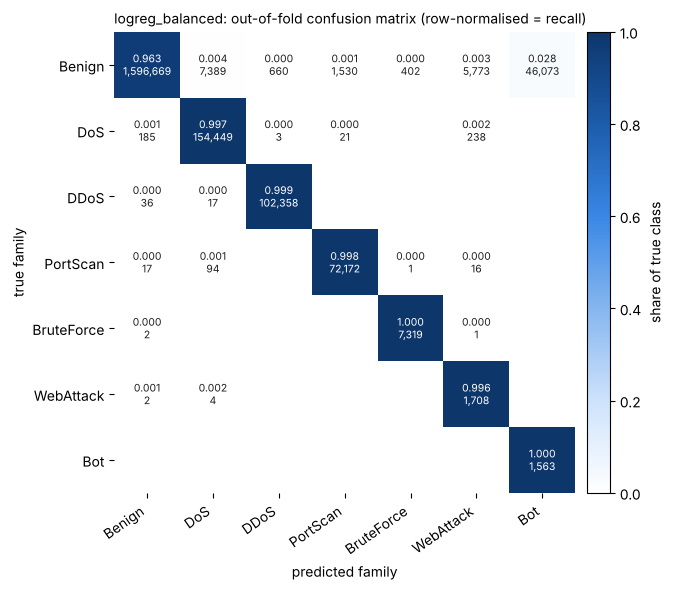

In [ ]:
best = max(["logreg_balanced", "tree_d8_balanced"], key=lambda n: FOLDS[n]["val_macro_f1"].mean())
cm = confusion_matrix(y, OOF[best], labels=ORDER)
cmn = cm / cm.sum(axis=1, keepdims=True)
blue = LinearSegmentedColormap.from_list("seq_blue", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(cmn, cmap=blue, vmin=0, vmax=1)
for i in range(len(ORDER)):
    for j in range(len(ORDER)):
        if cm[i, j]:
            ax.text(j, i, f"{cmn[i, j]:.3f}\n{cm[i, j]:,}", ha="center", va="center", fontsize=7.5,
                    color="white" if cmn[i, j] > 0.55 else "#1f1f1f")
ax.set_xticks(range(len(ORDER)), ORDER, rotation=35, ha="right")
ax.set_yticks(range(len(ORDER)), ORDER)
ax.set_xlabel("predicted family")
ax.set_ylabel("true family")
ax.set_title(f"{best}: out-of-fold confusion matrix (row-normalised = recall)", fontsize=10, loc="left")
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="share of true class")
fig.tight_layout()
fig.savefig(f"{REPORTS}/confusion_{best}.png", dpi=150)
plt.show()

## 10. Shortcut ablations (decision tree)

In [ ]:
INIT = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]
tree = lambda: DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEED)
ABL = {
    "tree_no_port": pipe(tree(), use_port=False),
    "tree_no_init_win": pipe(tree(), feats=[c for c in FEATS if c not in INIT]),
}
for name, m in ABL.items():
    cols = [c for c in FEATS if not (name == "tree_no_init_win" and c in INIT)]
    t = time.time()
    FOLDS[name], OOF[name], _ = cv_evaluate(m, X[cols], y, SEED, train_scores=False)
    print(f"{name:18s} {time.time() - t:6.0f}s")
abl = pd.DataFrame({n: {"macro_f1": FOLDS[n]["val_macro_f1"].mean(), "benign_fpr": FOLDS[n]["val_benign_fpr"].mean(), "pr_auc": FOLDS[n]["val_pr_auc"].mean()}
                    for n in ["tree_d8_balanced", "tree_no_port", "tree_no_init_win"]}).T
abl["Δ_macro_f1"] = abl["macro_f1"] - abl.loc["tree_d8_balanced", "macro_f1"]
per = pd.DataFrame({n: pd.DataFrame(classification_report(y, OOF[n], labels=ORDER, output_dict=True, zero_division=0)).T.loc[ORDER, "f1-score"]
                    for n in ["tree_d8_balanced", "tree_no_port", "tree_no_init_win"]})
display(abl.round(4), per.round(4))

tree_no_port          406s


tree_no_init_win      377s


,macro_f1,benign_fpr,pr_auc,Δ_macro_f1
tree_d8_balanced,0.7593,0.0258,0.9966,0.0000
tree_no_port,0.6570,0.0604,0.9875,-0.1023
tree_no_init_win,0.7777,0.0485,0.9970,0.0184


,tree_d8_balanced,tree_no_port,tree_no_init_win
Benign,0.9869,0.9679,0.9751
DoS,0.9777,0.9619,0.9736
DDoS,0.9977,0.9963,0.9983
PortScan,0.9931,0.9948,0.9917
BruteForce,0.7934,0.5232,0.7530
WebAttack,0.4671,0.0703,0.7024
Bot,0.0976,0.0835,0.0453


In [ ]:
out = {
    "rows_dev": int(len(y)), "rows_test_sealed": int(TEST_ROWS), "dev_conflicts_dropped": int(c_dev.sum()), "test_conflict_rows": int(c_test.sum()),
    "cv": {n: {c: [float(f[c].mean()), float(f[c].std(ddof=1))] for c in f.columns if c not in ("fold", "sec")} for n, f in FOLDS.items()},
}
json.dump(out, open(f"{REPORTS}/baselines_cv.json", "w"), indent=1)
print("saved", f"{REPORTS}/baselines_cv.json")

saved ../reports/baselines_cv.json
